In [18]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np


# 1.1
В государстве 100 городов, и из каждого из них выходит 4 дороги. Сколько всего дорог в государстве?

In [ ]:
def calculate_roads(num_cities: int, degree_per_city: int) -> int:
    sum_degrees = num_cities * degree_per_city
    total_roads = sum_degrees // 2
    return total_roads

cities = 100
degree = 4

total_roads = calculate_roads(cities, degree)
print(f"Порядок графа |V|: {cities}")
print(f"Степень каждой вершины deg(v): {degree}")
print(f"Сумма степеней sum(deg(v)): {cities * degree}")
print(f"Количество дорог |E| = {cities * degree} / 2 = {total_roads}")

Порядок графа |V|: 100
Степень каждой вершины deg(v): 4
Сумма степеней sum(deg(v)): 400
Количество дорог |E| = 400 / 2 = 200


# 1.2

Может ли в государстве, в котором из каждого города выходит 3 дороги, быть ровно 100 дорог?

In [25]:
def check_graph_existence(total_roads: int, degree_per_city: int) -> dict:
    sum_degrees = 2 * total_roads
    is_integer = (sum_degrees % degree_per_city == 0)
    num_cities = sum_degrees / degree_per_city

    return {
        "2 * |E|": sum_degrees, #найдем суммарную степень для всего графа
        "deg(v)": degree_per_city, #по условию какая степень города
        "|V|": num_cities, #можем вычислить количество городов, зная суммарную степень и степень каждого города отдельно
        "is_integer": is_integer, 
        "possible": is_integer #если не целое, то не может
    }

result = check_graph_existence(total_roads=100, degree_per_city=3)
print(f"2 * |E| = {result['2 * |E|']}")
print(f"Степень deg(v) = {result['deg(v)']}")
print(f"Городов |V| = {result['2 * |E|']} / {result['deg(v)']} = {result['|V|']:.4f}")
print(f"Вывод: такое государство существовать {'может' if result['possible'] else 'не может'}.")

2 * |E| = 200
Степень deg(v) = 3
Городов |V| = 200 / 3 = 66.6667
Вывод: такое государство существовать не может.


# 1.3
Определить порядок и размер следующего графа. Определить степени всех вершин.

In [31]:
def deg_size(G):
    #Определить порядок и размер
    order = G.number_of_nodes()
    print(f"Порядок графа 1 (|V|): {order}")
    
    size = G.number_of_edges()
    print(f"Размер графа 1 (|E|): {size}")
    
    #определить степени всех вершин
    degrees = dict(G.degree())
    print("Степени вершин:")
    for node in sorted(degrees.keys()):
        print(f"  deg({node}) = {degrees[node]}")
    print(f"Сумма степеней: {sum(degrees.values())} (должна быть 2 * {size} = {2 * size})")


Порядок графа 1 (|V|): 4
Размер графа 1 (|E|): 7
Степени вершин:
  deg(a) = 4
  deg(b) = 3
  deg(c) = 4
  deg(d) = 3
Сумма степеней: 14 (должна быть 2 * 7 = 14)


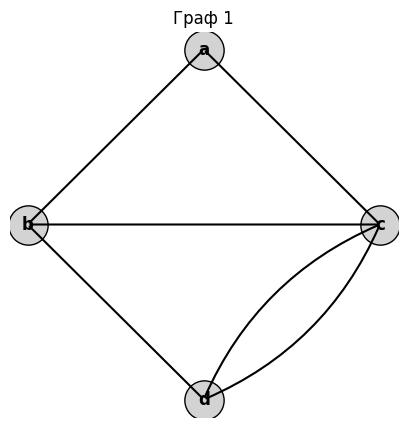

In [33]:
G1 = nx.MultiGraph()
vertices_1 = ['a', 'b', 'c', 'd']
G1.add_nodes_from(vertices_1)
edges_1 = [
    ('a', 'b', {'id': 1}),
    ('b', 'c', {'id': 2}),
    ('b', 'd', {'id': 3}),
    ('a', 'c', {'id': 4}),
    ('c', 'd', {'id': 5}),
    ('c', 'd', {'id': 6}),
    ('a', 'a', {'id': 7}),  #петля
]
for u, v, data in edges_1:
    G1.add_edge(u, v, **data)

deg_size(G1)

#viz
pos_1 = {'a': (0, 1), 'b': (-1, 0), 'c': (1, 0), 'd': (0, -1)}
fig, ax = plt.subplots(figsize=(5, 5))
nx.draw_networkx_nodes(G1, pos_1, ax=ax, node_color='lightgray', edgecolors='black', node_size=800)
nx.draw_networkx_labels(G1, pos_1, ax=ax, font_size=12, font_weight='bold')

#ребра без перекрытия
for u, v, k, d in G1.edges(keys=True, data=True):
    rad = 0.2 if k == 1 else (-0.2 if k == 0 and u != v and G1.number_of_edges(u, v) > 1 else 0.0)
    connectionstyle = f"arc3,rad={rad}" if u != v else "arc3,rad=0.5"
    ax.annotate("", xy=pos_1[v], xytext=pos_1[u],
                arrowprops=dict(arrowstyle="-", connectionstyle=connectionstyle, lw=1.5))

ax.set_title("Граф 1")
ax.axis('off')
plt.show()

Порядок графа 1 (|V|): 7
Размер графа 1 (|E|): 4
Степени вершин:
  deg(A) = 1
  deg(B) = 2
  deg(C) = 2
  deg(D) = 1
  deg(E) = 0
  deg(F) = 1
  deg(G) = 1
Сумма степеней: 8 (должна быть 2 * 4 = 8)


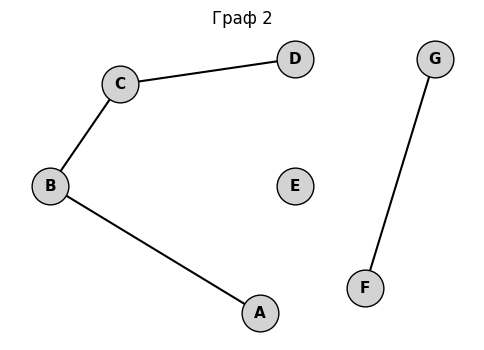

In [34]:
G2 = nx.Graph()
vertices_2 = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
G2.add_nodes_from(vertices_2)
edges_2 = [
    ('A', 'B'),
    ('B', 'C'),
    ('C', 'D'),
    ('F', 'G')
]
G2.add_edges_from(edges_2)

deg_size(G2)


# Визуализация
pos_2 = {
    'A': (0.8, 0.0),
    'B': (0.2, 0.5),
    'C': (0.4, 0.9),
    'D': (0.9, 1.0),
    'E': (0.9, 0.5),
    'F': (1.1, 0.1),
    'G': (1.3, 1.0)
}

fig, ax = plt.subplots(figsize=(6, 4))
nx.draw_networkx_nodes(G2, pos_2, ax=ax, node_color='lightgray', edgecolors='black', node_size=700)
nx.draw_networkx_edges(G2, pos_2, ax=ax, width=1.5)
nx.draw_networkx_labels(G2, pos_2, ax=ax, font_size=11, font_weight='bold')

ax.set_title("Граф 2")
ax.axis('off')
plt.show()

Порядок графа 1 (|V|): 5
Размер графа 1 (|E|): 9
Степени вершин:
  deg(2) = 4
  deg(3) = 3
  deg(4) = 4
  deg(5) = 2
  deg(6) = 5
Сумма степеней: 18 (должна быть 2 * 9 = 18)


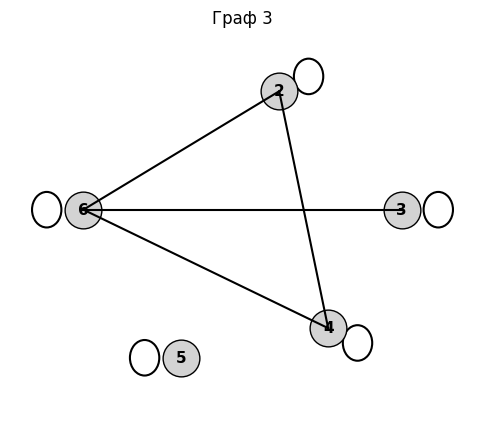

In [38]:
G3 = nx.MultiGraph()

vertices_3 = [2, 3, 4, 5, 6]
G3.add_nodes_from(vertices_3)
simple_edges = [
    (6, 2),
    (6, 3),
    (6, 4),
    (2, 4)
]
G3.add_edges_from(simple_edges)
loops = [(v, v) for v in vertices_3]
G3.add_edges_from(loops)

deg_size(G3)

#viz
pos_3 = {
    6: (0.0, 0.5),
    2: (0.8, 0.9),
    3: (1.3, 0.5),
    4: (1.0, 0.1),
    5: (0.4, 0.0)
}

fig, ax = plt.subplots(figsize=(6, 5))
nx.draw_networkx_nodes(G3, pos_3, ax=ax, node_color='lightgray', edgecolors='black', node_size=700)
nx.draw_networkx_labels(G3, pos_3, ax=ax, font_size=11, font_weight='bold')

#прямые ребер
for u, v in simple_edges:
    ax.plot([pos_3[u][0], pos_3[v][0]], [pos_3[u][1], pos_3[v][1]], color='black', lw=1.5)

#отрисовка петель
loop_offsets = {6: (-0.15, 0), 2: (0.12, 0.05), 3: (0.15, 0), 4: (0.12, -0.05), 5: (-0.15, 0)}
for v, (dx, dy) in loop_offsets.items():
    circle = plt.Circle((pos_3[v][0] + dx, pos_3[v][1] + dy), 0.06, color='black', fill=False, lw=1.5)
    ax.add_patch(circle)

ax.set_xlim(-0.3, 1.6)
ax.set_ylim(-0.2, 1.1)
ax.set_title("Граф 3")
ax.axis('off')
plt.show()

Порядок графа 4 (|V|): 8
Размер графа 4 (|E|): 17

Степени вершин орграфа:
Вершина deg-(вход)    deg+(исход)   deg(полная)   
--------------------------------------------------
a       0             5             5             
b       1             2             3             
c       4             0             4             
d       1             2             3             
e       3             1             4             
f       4             3             7             
g       2             2             4             
h       2             2             4             
--------------------------------------------------
Сумма:  17            17            34            
Проверка: sum(deg-) = sum(deg+) = 17; sum(deg) = 2 * 17 = 34


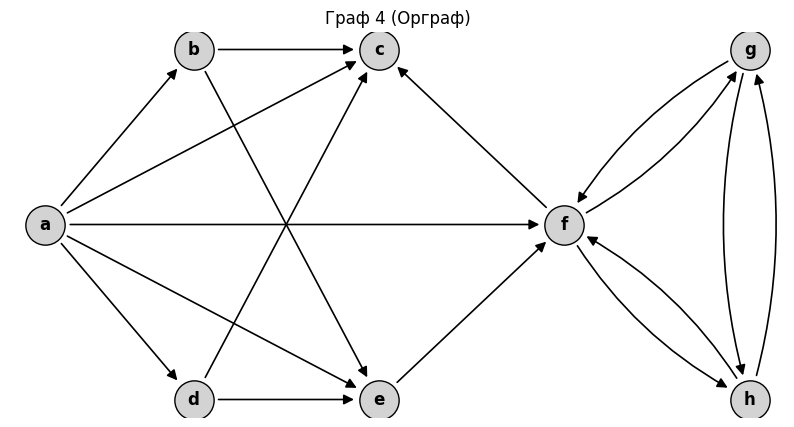

In [8]:
# Инициализация ориентированного мультиграфа
D = nx.MultiDiGraph()

# Добавление вершин
nodes_4 = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h']
D.add_nodes_from(nodes_4)

# Добавление дуг
directed_edges = [
    # Из a
    ('a', 'b'), ('a', 'c'), ('a', 'd'), ('a', 'e'), ('a', 'f'),
    # Из b
    ('b', 'c'), ('b', 'e'),
    # Из d
    ('d', 'c'), ('d', 'e'),
    # Из e
    ('e', 'f'),
    # Из f
    ('f', 'c'), ('f', 'g'), ('f', 'h'),
    # Из g
    ('g', 'f'), ('g', 'h'),
    # Из h
    ('h', 'f'), ('h', 'g')
]

D.add_edges_from(directed_edges)

order_4 = D.number_of_nodes()
size_4 = D.number_of_edges()

in_degrees = dict(D.in_degree())
out_degrees = dict(D.out_degree())
total_degrees = {v: in_degrees[v] + out_degrees[v] for v in nodes_4}

print(f"Порядок графа 4 (|V|): {order_4}")
print(f"Размер графа 4 (|E|): {size_4}")
print("\nСтепени вершин орграфа:")
print(f"{'Вершина':<8}{'deg-(вход)':<14}{'deg+(исход)':<14}{'deg(полная)':<14}")
print("-" * 50)
for node in nodes_4:
    print(f"{node:<8}{in_degrees[node]:<14}{out_degrees[node]:<14}{total_degrees[node]:<14}")

print("-" * 50)
print(f"{'Сумма:':<8}{sum(in_degrees.values()):<14}{sum(out_degrees.values()):<14}{sum(total_degrees.values()):<14}")
print(f"Проверка: sum(deg-) = sum(deg+) = {size_4}; sum(deg) = 2 * {size_4} = {2 * size_4}")

# Визуализация
pos_4 = {
    'a': (0.0, 0.5),
    'b': (0.4, 0.9),
    'd': (0.4, 0.1),
    'c': (0.9, 0.9),
    'e': (0.9, 0.1),
    'f': (1.4, 0.5),
    'g': (1.9, 0.9),
    'h': (1.9, 0.1)
}

fig, ax = plt.subplots(figsize=(10, 5))
nx.draw_networkx_nodes(D, pos_4, ax=ax, node_color='lightgray', edgecolors='black', node_size=800)
nx.draw_networkx_labels(D, pos_4, ax=ax, font_size=12, font_weight='bold')

# Отрисовка дуг с искривлением для антипараллельных пар
for u, v in directed_edges:
    rad = 0.15 if (v, u) in directed_edges else 0.0
    ax.annotate("", xy=pos_4[v], xytext=pos_4[u],
                arrowprops=dict(arrowstyle="-|>", color="black",
                                connectionstyle=f"arc3,rad={rad}", lw=1.2,
                                shrinkA=18, shrinkB=18, mutation_scale=15))

ax.set_title("Граф 4 (Орграф)")
ax.axis('off')
plt.show()

# 1.4

--- 1.4 Граф 1 ---
Вершин: 4, Ребер: 7
Граф планарен (отображается плоская укладка)



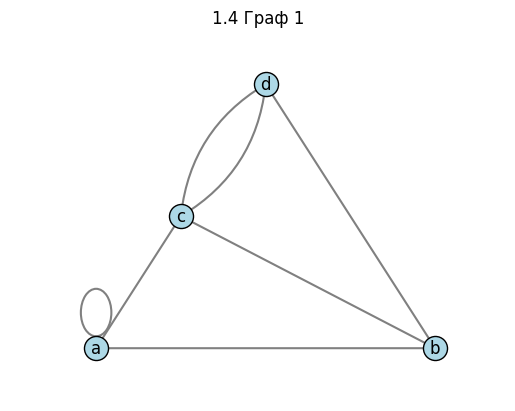

--- 1.4 Граф 2 ---
Вершин: 7, Ребер: 8
Граф планарен (отображается плоская укладка)



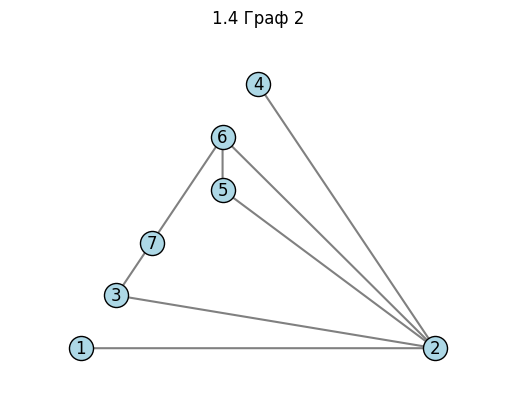

--- 1.4 Граф 3 ---
Вершин: 5, Ребер: 6
Граф планарен (отображается плоская укладка)



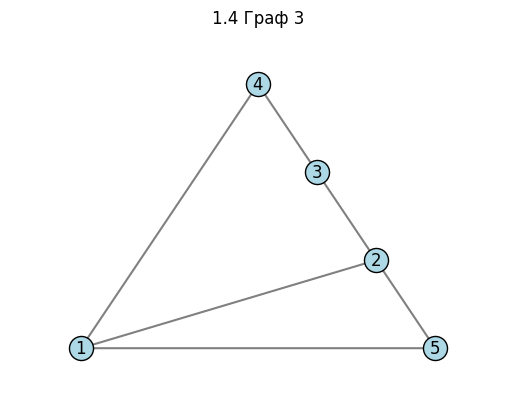

--- 1.4 Граф 4 (а) ---
Вершин: 5, Ребер: 8
Граф планарен (отображается плоская укладка)



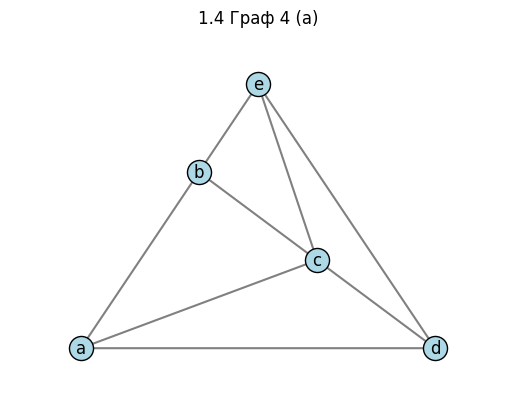

--- 1.4 Граф 5 (б) ---
Вершин: 5, Ребер: 8
Граф планарен (отображается плоская укладка)



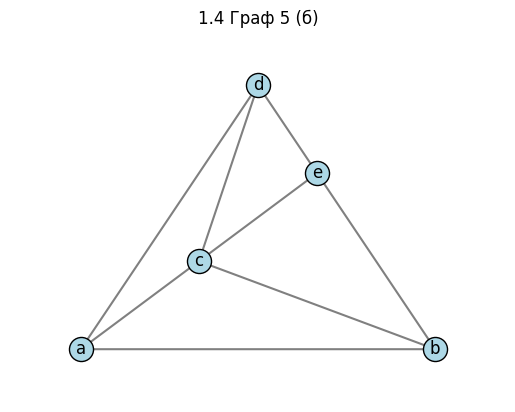

--- 1.4 Граф 6 (x1-x10) ---
Вершин: 10, Ребер: 21
Граф планарен (отображается плоская укладка)



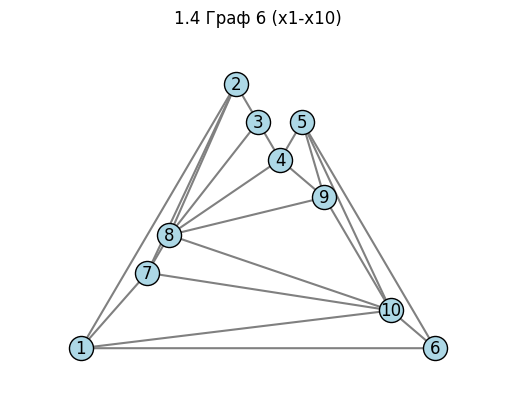

In [12]:
import matplotlib.patches as patches

def process_graph(title, G):
    G_simple = nx.Graph(G)
    G_simple.remove_edges_from(nx.selfloop_edges(G_simple))
    is_planar, _ = nx.check_planarity(G_simple)

    print(f"--- {title} ---")
    print(f"Вершин: {G.number_of_nodes()}, Ребер: {G.number_of_edges()}")
    if is_planar:
        print("Граф планарен (отображается плоская укладка)\n")
        pos = nx.planar_layout(G_simple)
    else:
        print("Граф НЕ планарен\n")
        pos = nx.circular_layout(G_simple)

    fig, ax = plt.subplots()
    nx.draw_networkx_nodes(G, pos, node_color="lightblue", edgecolors="black", ax=ax)
    nx.draw_networkx_labels(G, pos, ax=ax)

    counts = {}
    for u, v in G.edges():
        if u != v:
            pair = tuple(sorted([u, v]))
            counts[pair] = counts.get(pair, 0) + 1

    seen = {}
    for u, v in G.edges():
        if u == v:
            ax.add_patch(patches.Circle((pos[u][0], pos[u][1] + 0.12), 0.08, fill=False, color="gray", lw=1.5))
        else:
            pair = tuple(sorted([u, v]))
            seen[pair] = seen.get(pair, 0) + 1
            rad = 0.0 if counts[pair] == 1 else (0.25 if seen[pair] % 2 == 1 else -0.25)
            ax.add_patch(patches.FancyArrowPatch(pos[u], pos[v], connectionstyle=f"arc3,rad={rad}", arrowstyle="-", color="gray", lw=1.5))

    ax.set_title(title)
    ax.axis("off")
    ax.margins(0.2)
    plt.show()

g1 = nx.MultiGraph()
g1.add_edges_from([('a', 'b'), ('a', 'c'), ('b', 'c'), ('b', 'd'), ('c', 'd'), ('c', 'd'), ('a', 'a')])

graphs = [
    ("1.4 Граф 1", g1),
    ("1.4 Граф 2", nx.Graph([(1, 2), (2, 3), (2, 4), (2, 5), (2, 6), (3, 7), (6, 7), (5, 6)])),
    ("1.4 Граф 3", nx.Graph([(1, 2), (1, 4), (1, 5), (2, 3), (2, 5), (3, 4)])),
    ("1.4 Граф 4 (а)", nx.Graph([('a', 'b'), ('a', 'd'), ('b', 'e'), ('d', 'e'), ('a', 'c'), ('b', 'c'), ('c', 'd'), ('c', 'e')])),
    ("1.4 Граф 5 (б)", nx.Graph([('a', 'b'), ('a', 'c'), ('a', 'd'), ('b', 'c'), ('b', 'e'), ('c', 'e'), ('c', 'd'), ('e', 'd')])),
    ("1.4 Граф 6 (x1-x10)", nx.Graph([
        (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 1),
        (6, 10), (3, 8), (1, 10), (5, 10), (2, 8), (4, 8), (10, 8),
        (1, 7), (2, 7), (10, 7), (8, 7),
        (5, 9), (4, 9), (10, 9), (8, 9)
    ]))
]

for title, G in graphs:
    process_graph(title, G)

# 1.5


--- 1.5 а) K3 ---
Вершин: 3, Ребер: 3
Граф планарен (viz плоский)



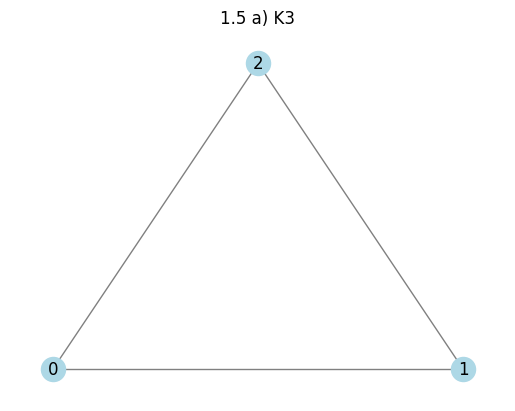

--- 1.5 б) K4 ---
Вершин: 4, Ребер: 6
Граф планарен (viz плоский)



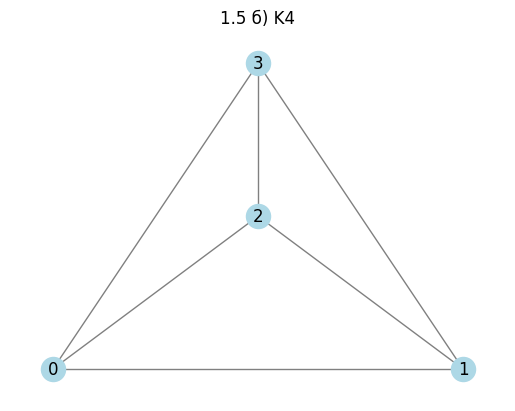

--- 1.5 в) K5 ---
Вершин: 5, Ребер: 10
Граф НЕ планарен



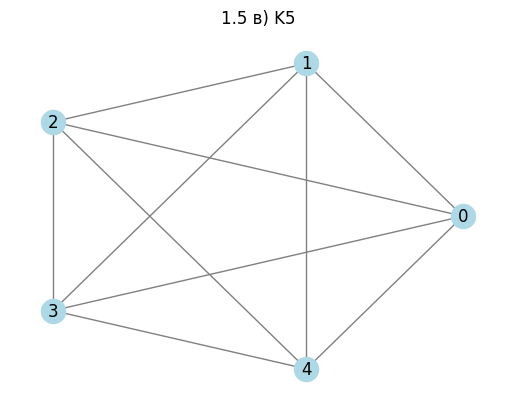

--- 1.5 г) K8 ---
Вершин: 8, Ребер: 28
Граф НЕ планарен



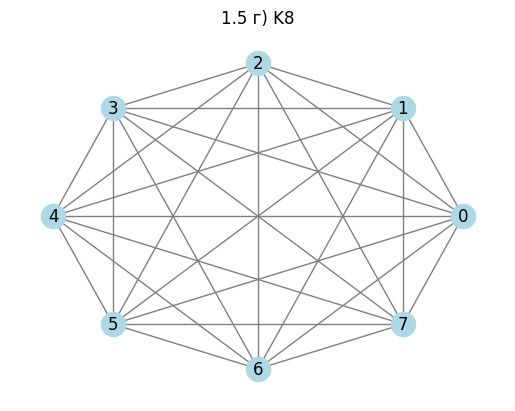

In [10]:
def process_graph(title, G):
    is_planar, _ = nx.check_planarity(G)
    print(f"--- {title} ---")
    print(f"Вершин: {G.number_of_nodes()}, Ребер: {G.number_of_edges()}")
    if is_planar:
        print("Граф планарен (viz плоский)\n")
        pos = nx.planar_layout(G)
    else:
        print("Граф НЕ планарен\n")
        pos = nx.circular_layout(G)

    plt.figure()
    plt.title(title)
    nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray")
    plt.show()

graphs = [
    
    ("1.5 а) K3", nx.complete_graph(3)),
    ("1.5 б) K4", nx.complete_graph(4)),
    ("1.5 в) K5", nx.complete_graph(5)),
    ("1.5 г) K8", nx.complete_graph(8))
]

for title, G in graphs:
    process_graph(title, G)

# 1.6
Определить число возможных простых путей между вершинами a и c


--- 1.6 Граф 1 ---
Число простых путей между a и c: 4
a -> c
a -> b -> c
a -> e -> c
a -> e -> d -> c



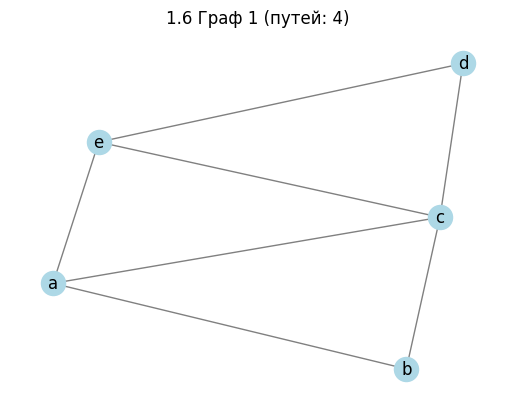

--- 1.6 Граф 2 ---
Число простых путей между 1 и 5: 43
1 -> 5
1 -> 7 -> 5
1 -> 2 -> 7 -> 5
1 -> 2 -> 6 -> 5
1 -> 7 -> 6 -> 5
1 -> 2 -> 3 -> 4 -> 5
1 -> 2 -> 3 -> 7 -> 5
1 -> 2 -> 3 -> 6 -> 5
1 -> 2 -> 7 -> 6 -> 5
1 -> 2 -> 6 -> 7 -> 5
1 -> 2 -> 6 -> 4 -> 5
1 -> 7 -> 6 -> 4 -> 5
1 -> 7 -> 2 -> 6 -> 5
1 -> 7 -> 3 -> 4 -> 5
1 -> 7 -> 3 -> 6 -> 5
1 -> 2 -> 3 -> 4 -> 6 -> 5
1 -> 2 -> 3 -> 7 -> 6 -> 5
1 -> 2 -> 3 -> 6 -> 7 -> 5
1 -> 2 -> 3 -> 6 -> 4 -> 5
1 -> 2 -> 7 -> 6 -> 4 -> 5
1 -> 2 -> 7 -> 3 -> 4 -> 5
1 -> 2 -> 7 -> 3 -> 6 -> 5
1 -> 2 -> 6 -> 3 -> 4 -> 5
1 -> 2 -> 6 -> 3 -> 7 -> 5
1 -> 7 -> 6 -> 3 -> 4 -> 5
1 -> 7 -> 2 -> 3 -> 4 -> 5
1 -> 7 -> 2 -> 3 -> 6 -> 5
1 -> 7 -> 2 -> 6 -> 4 -> 5
1 -> 7 -> 3 -> 2 -> 6 -> 5
1 -> 7 -> 3 -> 4 -> 6 -> 5
1 -> 7 -> 3 -> 6 -> 4 -> 5
1 -> 2 -> 3 -> 4 -> 6 -> 7 -> 5
1 -> 2 -> 3 -> 7 -> 6 -> 4 -> 5
1 -> 2 -> 7 -> 6 -> 3 -> 4 -> 5
1 -> 2 -> 7 -> 3 -> 4 -> 6 -> 5
1 -> 2 -> 7 -> 3 -> 6 -> 4 -> 5
1 -> 2 -> 6 -> 7 -> 3 -> 4 -> 5
1 -> 2 -> 6 -> 4 -> 3 -> 7 -> 5

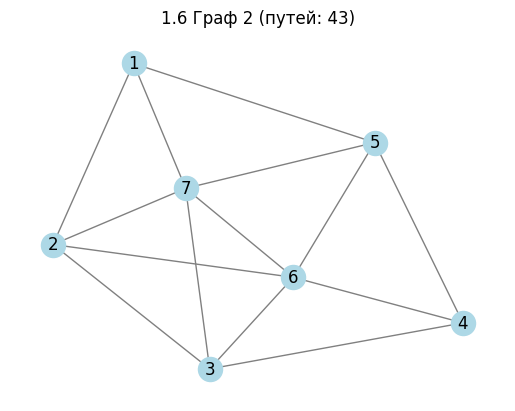

In [ ]:
def process_graph(title, G, start, end):
    paths = list(nx.all_simple_paths(G, start, end))
    print(f"--- {title} ---")
    print(f"Число простых путей между {start} и {end}: {len(paths)}")
    for p in sorted(paths, key=len):
        print(" -> ".join(map(str, p)))
    print()

    plt.figure()
    plt.title(f"{title} (путей: {len(paths)})")
    nx.draw(G, with_labels=True, node_color="lightblue", edge_color="gray")
    plt.show()

g1 = nx.Graph([
    ('a', 'b'), ('b', 'c'), ('c', 'd'), ('d', 'e'),
    ('e', 'a'), ('e', 'c'), ('a', 'c')
])

g2 = nx.Graph([
    (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 1),
    (1, 5), (7, 2), (7, 3), (7, 5), (6, 2), (6, 3), (6, 4)
])

process_graph("1.6 Граф 1", g1, 'a', 'c')
process_graph("1.6 Граф 2", g2, 1, 5)

# 1.7
Докажите, что на рёбрах связного графа можно так расставить стрелки, чтобы из некоторой вершины можно было добраться по стрелкам до любой другой.

1. Граф конечный и связный => $\exists$ остовное дерево в этом графе
2. Выбираем вершину на этом остовном дереве. Делаем её корнем. 
2.0. Мы можем сделать любую вершину корнем, потому что у дерева есть свойство, что между любыми двумя вершинами есть ровно один простой путь. 

# 1.8
Доказать, что число штатов США с нечётным числом соседей чётно.

Сумма ребер равна 2|E|.

$d(v)_{чет}$ - степень вершины с четным числом соседей. Это, по определению, четное число. 

$2|E| = \sum d(v)_{нечет} + \sum d(v)_{чет}$

$\sum d(v)_{чет}$ - четное число, $2|E|$ - четное число, значит $\sum d(v)_{нечет}$ - четное число 



# 1.9
Резидент одной иностранной разведки сообщил в центр о готовящемся подписании ряда двусторонних соглашений между пятнадцатью бывшими республиками СССР. Согласно его донесению, каждая из них заключит договор ровно с тремя другими.

Заслуживает ли резидент доверия?

Двустороннее соглашение <=> двустороннее ребро, т.е. граф будет неориентированным.

Получается, что степени всех вершин равны 3, количество вершин 15

$15\cdot3=45$ вершин. Нечетное число, по лемме о рукопожатиях такого графа не существует. 

Не заслуживает.

# 1.10
Какие-то две команды набрали в круговом волейбольном турнире одинаковое число очков.
Докажите, что найдутся такие команды А, В и С, что А выиграла у В, В выиграла у С, а С выиграла у А.

Представим турнир как орграф. Это граф, где каждые две вершины соеденины ребром (круговой турнир). 

1. Допустим, что такой тройки нет. 

2. Это означает, что нет обратных рёбер (ориентированных циклов), что делает все степени выхоядщих ребер вершин рядом n-1, n-2, n-3, ..., 0.
2.1. Если они есть, то существует цикл - тройка. Любой цикл длиннее 3 вершин сводится к циклу из 3 вершин так как турнир круговой и каждая пара вершин связана ребром.
3. Ни одна из степеней не повторяется, что противоречит условию "две команды набрали одинаковое количество очков". Следовательно, предпосылка не верна, тройка существует.  

# 1.11
Докажите, что не существует графа с пятью вершинами, степени которых равны 4, 4, 4, 4, 2.

1. $G$ существует <=> $\overline{G}$ (дополнение) существует
1.0. Это так, потому что всегда можно провести недостающие рёбра и получить граф. 
2. Найдем степени вершин дополнения: 
2.1. Максимальная степень вершины в графе из 5 вершин - 4.
2.2. Вычтем текущие степени вершин: 4-4, 4-4, 4-4, 4-4, 4-2
2.3. получаются степени 0,0,0,0,2
3. Степени >2, когда все остальные степени равны 0, без петель быть не может => дополнение не существует => оригинальный граф не существует.

# 1.12

Могут ли степени вершин в графе быть равны:

a) 8, 6, 5, 4, 4, 3, 2, 2

б) 7, 7, 6, 5, 4, 2, 2, 1

в) 6, 6, 6, 5, 5, 3, 2, 2


а) нет, в простом графе из 8 вершин не может быть вершины со степенью 8.

б) нет, есть две вершины с максимальной степенью 7, но есть вершина со степенью 1. Две вершины степени 7 в простом графе соеденины со всеми остальными, значит минимальная степень графа равна 2. 

в) нет, сумма степеней равна 35, а 35 - нечетное число. По лемме рукопожатий сумма должна быть четной. 

# 1.13

В классе 30 человек. Может ли быть так, что 9 из них имеют по 3 друга (в этом классе), 11 — по 4 друга, а 10 — по 5 друзей?

Нет. $9\cdot3 + 11\cdot4 + 10\cdot5 = 121$, $121\text{ mod } 2 \neq 0$, по лемме о рукопожатиях число должно быть четным

# 1.14

--- Граф 1 (верхний левый) ---
Степени вершин: {1: 4, 2: 4, 3: 4, 5: 4, 6: 4, 4: 2}
Эйлеров цикл: [(1, 6), (6, 5), (5, 4), (4, 3), (3, 6), (6, 2), (2, 5), (5, 1), (1, 3), (3, 2), (2, 1)]



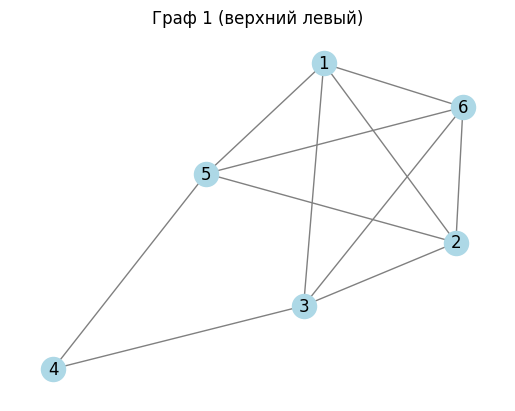

--- Граф 2 (верхний средний) ---
Степени вершин: {'a': 3, 'b': 2, 'c': 4, 'd': 2, 'e': 3}
Эйлеров цикл отсутствует. Вершины нечетной степени: ['a', 'e']



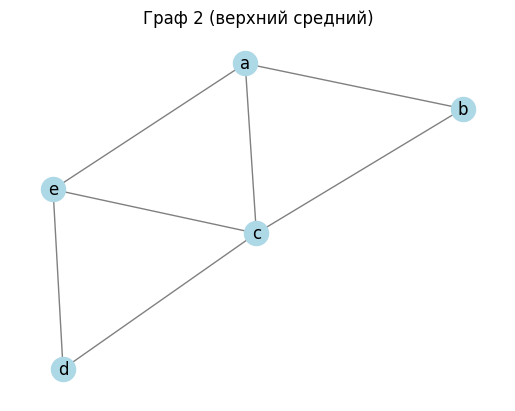

--- Граф 3 (верхний правый) ---
Степени вершин: {1: 3, 2: 4, 3: 4, 4: 3, 5: 4, 6: 5, 7: 5}
Эйлеров цикл отсутствует. Вершины нечетной степени: [1, 4, 6, 7]



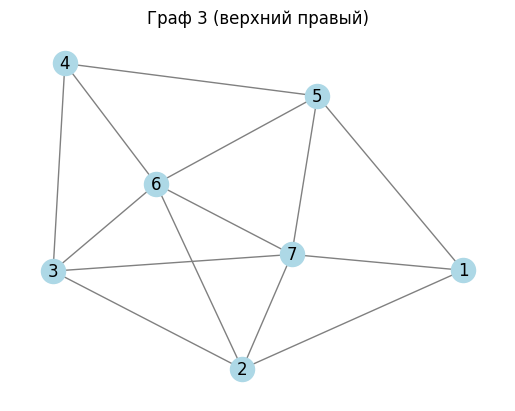

--- Граф 4 (а, две крыши) ---
Степени вершин: {1: 2, 2: 4, 3: 4, 5: 4, 4: 4, 6: 2}
Эйлеров цикл: [(1, 3), (3, 4), (4, 6), (6, 5), (5, 4), (4, 2), (2, 5), (5, 3), (3, 2), (2, 1)]



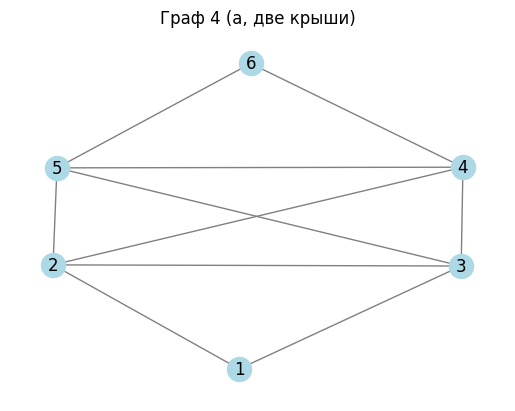

--- Граф 5 (б, одна крыша) ---
Степени вершин: {1: 2, 2: 4, 3: 4, 5: 3, 4: 3}
Эйлеров цикл отсутствует. Вершины нечетной степени: [5, 4]



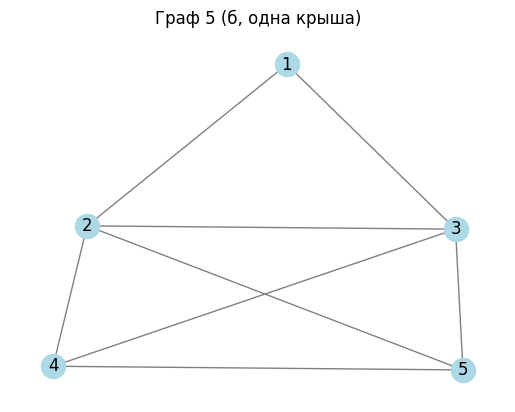

--- Граф 6 (в, K4) ---
Степени вершин: {0: 3, 1: 3, 2: 3, 3: 3}
Эйлеров цикл отсутствует. Вершины нечетной степени: [0, 1, 2, 3]



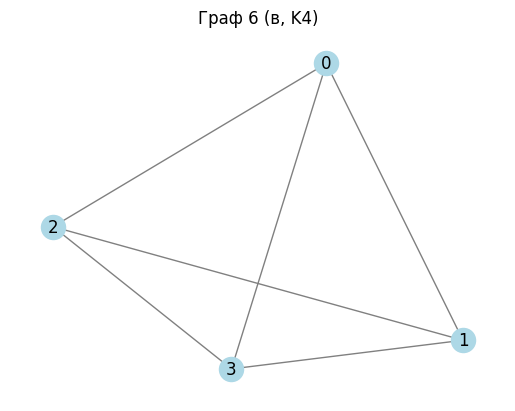

--- Граф 7  ---
Степени вершин: {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 3, 8: 3, 9: 3, 10: 3, 11: 3, 12: 3, 13: 3, 14: 3, 15: 3, 16: 3, 17: 3, 18: 3, 19: 3}
Эйлеров цикл отсутствует. Вершины нечетной степени: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]



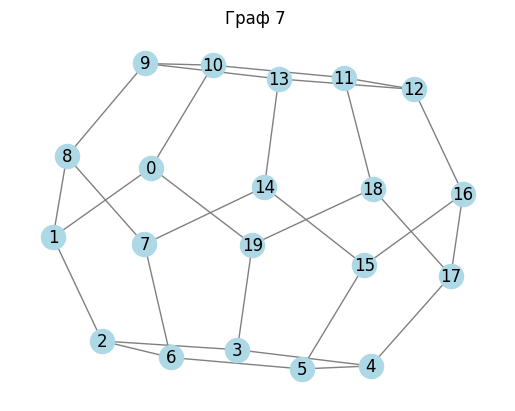

--- Граф 8  ---
Степени вершин: {0: 4, 2: 3, 3: 3, 10: 3, 11: 3, 1: 4, 12: 3, 13: 3, 4: 4, 7: 4, 5: 3, 6: 3, 8: 4, 9: 4}
Эйлеров цикл отсутствует. Вершины нечетной степени: [2, 3, 10, 11, 12, 13, 5, 6]



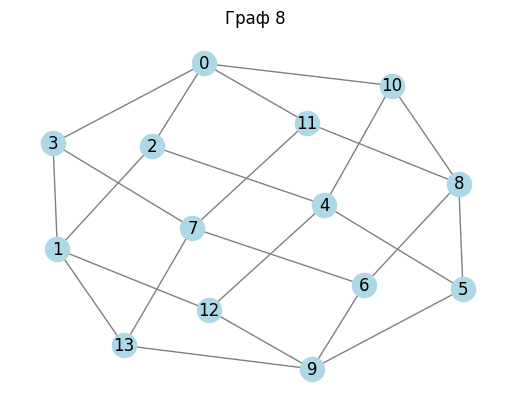

--- Граф 9  ---
Степени вершин: {0: 6, 1: 6, 2: 6, 3: 6, 4: 6, 5: 6, 6: 6}
Эйлеров цикл: [(0, 6), (6, 5), (5, 4), (4, 6), (6, 3), (3, 5), (5, 2), (2, 4), (4, 3), (3, 2), (2, 6), (6, 1), (1, 5), (5, 0), (0, 4), (4, 1), (1, 3), (3, 0), (0, 2), (2, 1), (1, 0)]



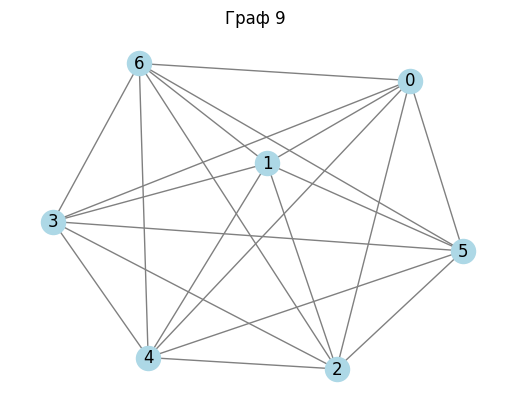

In [4]:
def process_graph(title, G):
    print(f"--- {title} ---")
    deg = dict(G.degree())
    print(f"Степени вершин: {deg}")
    if nx.is_eulerian(G):
        cycle = list(nx.eulerian_circuit(G))
        print(f"Эйлеров цикл: {cycle}\n")
    else:
        odd = [v for v, d in deg.items() if d % 2 != 0]
        print(f"Эйлеров цикл отсутствует. Вершины нечетной степени: {odd}\n")
    plt.figure()
    plt.title(title)
    nx.draw(G, with_labels=True, node_color="lightblue", edge_color="gray")
    plt.show()

graphs = [
    ("Граф 1 (верхний левый)", nx.Graph([(1, 2), (1, 3), (1, 5), (1, 6), (2, 3), (2, 5), (2, 6), (3, 4), (3, 6), (4, 5), (5, 6)])),
    ("Граф 2 (верхний средний)", nx.Graph([('a', 'b'), ('b', 'c'), ('c', 'd'), ('d', 'e'), ('e', 'a'), ('e', 'c'), ('a', 'c')])),
    ("Граф 3 (верхний правый)", nx.Graph([(1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 1), (1, 5), (2, 6), (2, 7), (3, 6), (3, 7), (4, 6), (5, 7)])),
    ("Граф 4 (а, две крыши)", nx.Graph([(1, 2), (1, 3), (2, 3), (3, 5), (5, 4), (4, 2), (2, 5), (3, 4), (6, 4), (6, 5)])),
    ("Граф 5 (б, одна крыша)", nx.Graph([(1, 2), (1, 3), (2, 3), (3, 5), (5, 4), (4, 2), (2, 5), (3, 4)])),
    ("Граф 6 (в, K4)", nx.complete_graph(4)),
    ("Граф 7 ", nx.dodecahedral_graph()),
    ("Граф 8 ", nx.Graph([(0, 2), (0, 3), (0, 10), (0, 11), (1, 2), (1, 3), (1, 12), (1, 13), (2, 4), (3, 7), (4, 5), (4, 10), (4, 12), (7, 6), (7, 11), (7, 13), (5, 8), (5, 9), (6, 8), (6, 9), (8, 10), (8, 11), (9, 12), (9, 13)])),
    ("Граф 9 ", nx.complete_graph(7))
]

for title, G in graphs:
    process_graph(title, G)

# 1.15

--- Граф 1 (верхний левый) ---
Гамильтонов цикл: [1, 2, 3, 4, 5, 6, 1]



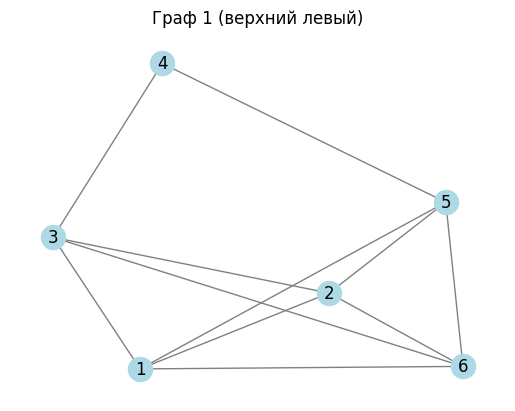

--- Граф 2 (верхний средний) ---
Гамильтонов цикл: ['a', 'b', 'c', 'd', 'e', 'a']



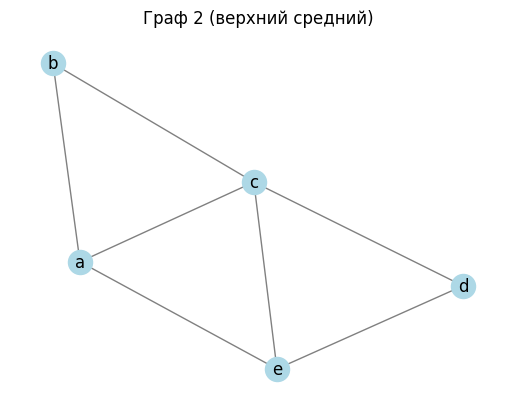

--- Граф 3 (верхний правый) ---
Гамильтонов цикл: [1, 2, 3, 4, 5, 6, 7, 1]



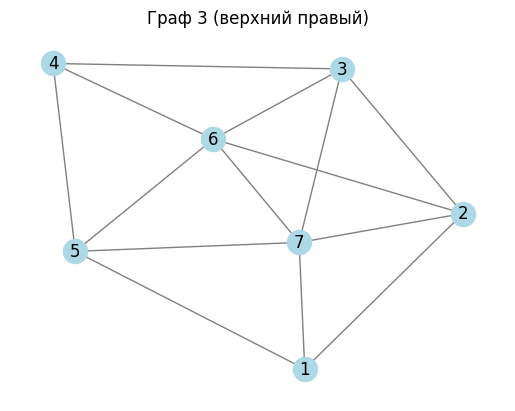

--- Граф 4 (а, две крыши) ---
Гамильтонов цикл: [1, 2, 4, 6, 5, 3, 1]



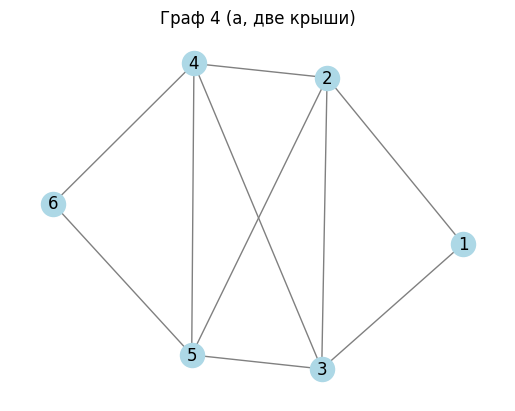

--- Граф 5 (б, одна крыша) ---
Гамильтонов цикл: [1, 2, 4, 5, 3, 1]



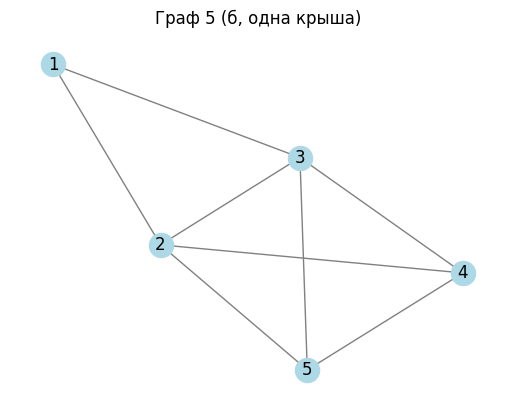

--- Граф 6 (в, K4) ---
Гамильтонов цикл: [0, 1, 2, 3, 0]



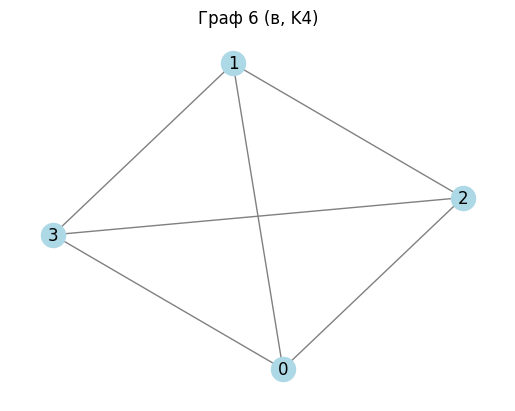

--- Граф 7  ---
Гамильтонов цикл: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 0]



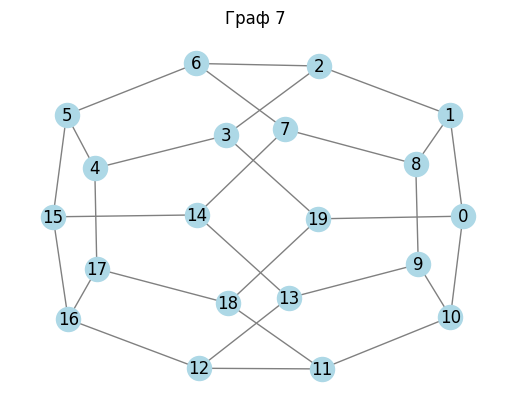

--- Граф 8  ---
Гамильтонов цикл отсутствует



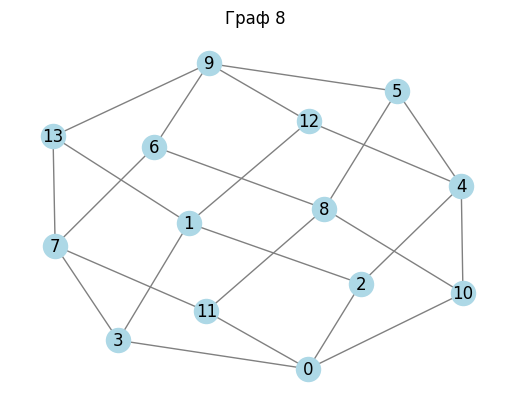

--- Граф 9  ---
Гамильтонов цикл: [0, 1, 2, 3, 4, 5, 6, 0]



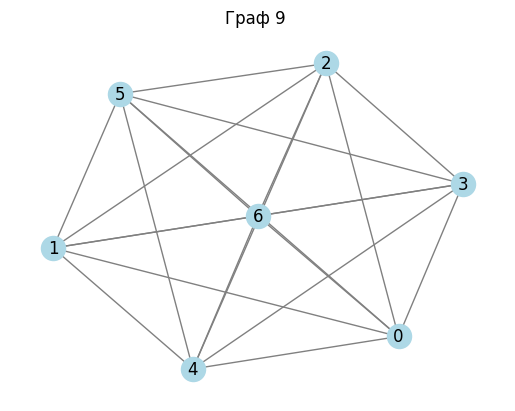

In [ ]:
def process_graph(title, G):
    nodes = list(G.nodes())
    n = len(nodes)

    def backtrack(curr, path, visited):
        if len(path) == n:
            return path + [nodes[0]] if nodes[0] in G[curr] else None
        for neighbor in G[curr]:
            if neighbor not in visited:
                visited.add(neighbor)
                res = backtrack(neighbor, path + [neighbor], visited)
                if res:
                    return res
                visited.remove(neighbor)
        return None

    cycle = backtrack(nodes[0], [nodes[0]], {nodes[0]}) if n >= 3 else None

    print(f"--- {title} ---")
    if cycle:
        print(f"Гамильтонов цикл: {cycle}\n")
    else:
        print("Гамильтонов цикл отсутствует\n")

    plt.figure()
    plt.title(title)
    nx.draw(G, with_labels=True, node_color="lightblue", edge_color="gray")
    plt.show()

graphs = [
    ("Граф 1 (верхний левый)", nx.Graph([(1, 2), (1, 3), (1, 5), (1, 6), (2, 3), (2, 5), (2, 6), (3, 4), (3, 6), (4, 5), (5, 6)])),
    ("Граф 2 (верхний средний)", nx.Graph([('a', 'b'), ('b', 'c'), ('c', 'd'), ('d', 'e'), ('e', 'a'), ('e', 'c'), ('a', 'c')])),
    ("Граф 3 (верхний правый)", nx.Graph([(1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 1), (1, 5), (2, 6), (2, 7), (3, 6), (3, 7), (4, 6), (5, 7)])),
    ("Граф 4 (а, две крыши)", nx.Graph([(1, 2), (1, 3), (2, 3), (3, 5), (5, 4), (4, 2), (2, 5), (3, 4), (6, 4), (6, 5)])),
    ("Граф 5 (б, одна крыша)", nx.Graph([(1, 2), (1, 3), (2, 3), (3, 5), (5, 4), (4, 2), (2, 5), (3, 4)])),
    ("Граф 6 (в, K4)", nx.complete_graph(4)),
    ("Граф 7 ", nx.dodecahedral_graph()),
    ("Граф 8 ", nx.Graph([(0, 2), (0, 3), (0, 10), (0, 11), (1, 2), (1, 3), (1, 12), (1, 13), (2, 4), (3, 7), (4, 5), (4, 10), (4, 12), (7, 6), (7, 11), (7, 13), (5, 8), (5, 9), (6, 8), (6, 9), (8, 10), (8, 11), (9, 12), (9, 13)])),
    ("Граф 9 ", nx.complete_graph(7))
]

for title, G in graphs:
    process_graph(title, G)